<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · The decoding mode changes the instruction stream

**Can a higher decoded-byte fraction identify the correct mode?**
We will ask the real VGI worker to decode one fixed byte string as both x86-64 and
x86-32. SQL will keep instruction rows, fallback bytes and diagnostics separate;
two charts will compare instruction boundaries and coverage.

The input is a **hand-authored, synthetic 16-byte teaching sequence**: a short
64-bit test/branch/arithmetic sequence ending in `ret`, followed by bytes `06 90`.
The final bytes expose how linear sweep continues beyond a return and resumes
after an undecodable byte. The worker only reads and decodes these bytes; the
notebook never executes them or treats the sweep as a control-flow trace.

## Choose one interpretation

`MODE` accepts `"x64"` (default) or `"x32"` (experiment). The byte string, x86
architecture and base address `4096` (`0x1000`) stay fixed. Both modes are calculated
as references; the parameter selects the instruction table and chart outline.
Restart the kernel and run all after editing. [Setup instructions](README.md).

In [1]:
MODE = "x64"

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Patch, Rectangle
from notebook_support import finish, prose, theme

if MODE not in {"x64", "x32"}:
    raise ValueError('MODE must be "x64" or "x32".')
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-disasm/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-disasm/notebooks/pyproject.toml.

## Connect to the published native release

`github-auto` downloads and verifies the pinned platform binary, then caches it.
No compiler or local worker checkout is needed for the notebook. The format probe
below identifies the bytes as raw input, with no container header supplying an
architecture or mode.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'disasm' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-disasm@v0.4.0');
CREATE OR REPLACE TABLE sample AS
SELECT from_hex('4885ff7406488d4701eb0231c0c30690') AS payload,
       4096::UBIGINT AS base_address;
SELECT hex(payload) AS input_hex, octet_length(payload) AS input_bytes,
       unnest(disasm.main.format(payload)) FROM sample;

,input_hex,input_bytes,container,arch,mode,bits,endian,entry
0,4885FF7406488D4701EB0231C0C30690,16,raw,None,None,<NA>,None,<NA>


## A diagnostic is not a decoded instruction

Raw bytes do not tell the worker which architecture to use. Calling `disassemble`
without one returns a size-zero diagnostic row. Keep it visible; counting this row
as an instruction would turn missing context into a misleading measurement.

In [5]:
%%sql
CREATE OR REPLACE TABLE diagnostic AS
SELECT * FROM disasm.main.disassemble(from_hex('4885ff7406488d4701eb0231c0c30690'));
SELECT address, size, mnemonic, op_str FROM diagnostic;

,address,size,mnemonic,op_str
0,0,0,(error),arch required for raw blob


## Supply explicit architecture and mode

Table-function inputs must be constant, so the two calls use the same literal
bytes and base address. Materialize each result once. A `.byte` row represents a
one-byte fallback when decoding fails; `(error)` is a diagnostic. The remaining
rows are decoded instructions, including instructions that linear sweep finds
after a return. None of these rows says the instruction was reached at runtime.

In [6]:
%%sql
CREATE OR REPLACE TABLE decoded AS
SELECT 'x64' AS mode, * FROM disasm.main.disassemble(
 from_hex('4885ff7406488d4701eb0231c0c30690'), arch := 'x86', mode := 'x64', base := 4096)
UNION ALL
SELECT 'x32' AS mode, * FROM disasm.main.disassemble(
 from_hex('4885ff7406488d4701eb0231c0c30690'), arch := 'x86', mode := 'x32', base := 4096);
CREATE OR REPLACE TABLE instruction_rows AS
SELECT d.*, address - base_address AS byte_offset,
 CASE WHEN mnemonic = '(error)' THEN 'Diagnostic'
      WHEN mnemonic = '.byte' THEN 'Fallback byte'
      WHEN list_contains(groups,'jump') THEN 'Jump'
      WHEN list_contains(groups,'ret') THEN 'Return'
      ELSE 'Other instruction' END AS kind
FROM decoded d CROSS JOIN sample;
SELECT mode, count(*) AS returned_rows, sum(size) AS represented_bytes
FROM instruction_rows GROUP BY mode ORDER BY mode;

,mode,returned_rows,represented_bytes
0,x32,10,16.0
1,x64,8,16.0


In [7]:
%%sql selected <<
SELECT byte_offset, printf('0x%x',address) AS address_hex,
 size AS bytes_consumed, hex(bytes) AS instruction_hex, mnemonic, op_str, groups, kind
FROM instruction_rows WHERE mode = '{{ MODE }}' ORDER BY address;

In [8]:
selected = globals()["selected"]
display(selected)
normal_rows = int((~selected.kind.isin(["Fallback byte", "Diagnostic"])).sum())
fallback_rows = int((selected.kind == "Fallback byte").sum())
prose(
    f"The **{MODE}** interpretation returns **{normal_rows} decoded instructions** and "
    f"**{fallback_rows} fallback-byte rows**. The addresses are based at `0x1000`; "
    "jump operands are displayed as absolute targets. The trailing rows remain visible "
    "even though a `ret` appears earlier in this linear sweep."
)

,byte_offset,address_hex,bytes_consumed,instruction_hex,mnemonic,op_str,groups,kind
0,0,0x1000,3,4885FF,test,"rdi, rdi",[],Other instruction
1,3,0x1003,2,7406,je,0x100b,"[branch_relative, jump]",Jump
2,5,0x1005,4,488D4701,lea,"rax, [rdi + 1]",[],Other instruction
3,9,0x1009,2,EB02,jmp,0x100d,"[branch_relative, jump]",Jump
4,11,0x100b,2,31C0,xor,"eax, eax",[],Other instruction
5,13,0x100d,1,C3,ret,,[ret],Return
6,14,0x100e,1,06,.byte,0x06,[],Fallback byte
7,15,0x100f,1,90,nop,,[],Other instruction


The **x64** interpretation returns **7 decoded instructions** and **1 fallback-byte rows**. The addresses are based at `0x1000`; jump operands are displayed as absolute targets. The trailing rows remain visible even though a `ret` appears earlier in this linear sweep.

## Compare boundaries on the same bytes

Every colored span consumes exactly its displayed number of input bytes. Jump and
return categories come from the worker's normalized groups; other decoded rows share
one category. Group tags can overlap (for example `jump` and `branch_relative`),
so we use one explicit category per row rather than summing tag counts.

In [9]:
%%sql spans <<
SELECT mode, byte_offset, size, mnemonic, op_str, kind
FROM instruction_rows ORDER BY mode, address;

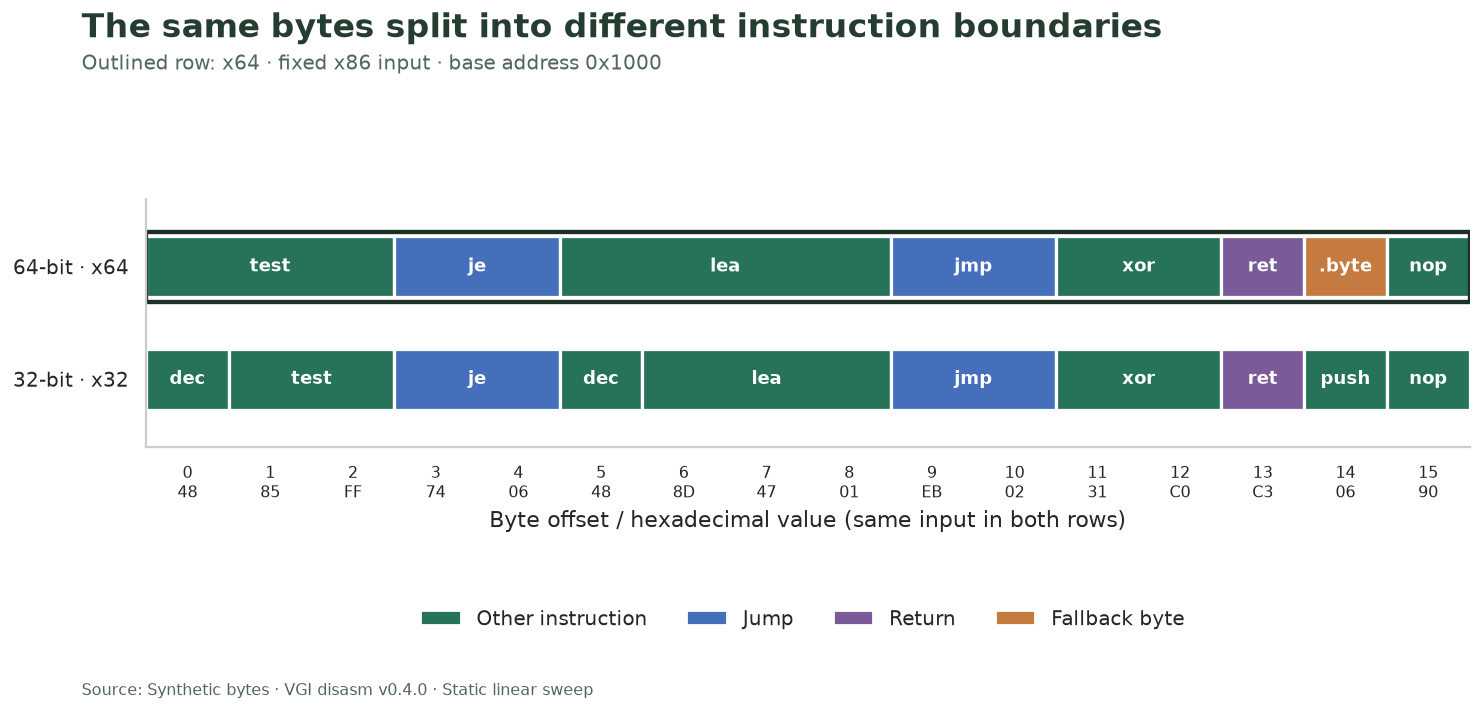

Compare offsets **0** and **5**: each `48` byte belongs to a larger instruction in the x64 result, but becomes a separate `dec eax` instruction in x32. At offset **14**, x64 emits a fallback `.byte`; x32 decodes `push es`. The final `nop` shows that the sweep continues after the fallback.

In [10]:
spans = globals()["spans"]
modes = ["x64", "x32"]
kind_colors = {
    "Other instruction": "#267358",
    "Jump": "#456fba",
    "Return": "#7a5a99",
    "Fallback byte": "#c57b40",
}
payload_hex = con.execute("SELECT hex(payload) FROM sample").fetchone()[0]
hex_bytes = [payload_hex[i : i + 2] for i in range(0, len(payload_hex), 2)]
fig, ax = plt.subplots(figsize=(11.8, 5.5))
for y, mode in enumerate(modes):
    for row in spans[spans["mode"] == mode].itertuples(index=False):
        ax.barh(
            y,
            row.size,
            left=row.byte_offset,
            height=0.54,
            color=kind_colors[row.kind],
            edgecolor="white",
            linewidth=1.8,
        )
        ax.text(
            row.byte_offset + row.size / 2,
            y,
            row.mnemonic,
            ha="center",
            va="center",
            color="white",
            fontsize=10,
            weight="bold",
        )
ax.add_patch(
    Rectangle(
        (0, modes.index(MODE) - 0.31),
        len(hex_bytes),
        0.62,
        fill=False,
        edgecolor="#1d3026",
        linewidth=2.4,
    )
)
ax.set_yticks([0, 1], ["64-bit · x64", "32-bit · x32"])
ax.set_xticks(
    np.arange(len(hex_bytes)) + 0.5,
    [f"{i}\n{value}" for i, value in enumerate(hex_bytes)],
    fontsize=9,
)
ax.set_xlim(0, len(hex_bytes))
ax.set_ylim(1.6, -0.6)
ax.set_xlabel("Byte offset / hexadecimal value (same input in both rows)")
ax.grid(False)
fig.legend(
    handles=[Patch(facecolor=color, label=kind) for kind, color in kind_colors.items()],
    loc="center",
    bbox_to_anchor=(0.55, 0.13),
    ncol=4,
    frameon=False,
)
finish(
    fig,
    "The same bytes split into different instruction boundaries",
    f"Outlined row: {MODE} · fixed x86 input · base address 0x1000",
    f"instruction-spans-{MODE}.png",
    bottom=0.22,
)
prose(
    "Compare offsets **0** and **5**: each `48` byte belongs to a larger instruction "
    "in the x64 result, but becomes a separate `dec eax` instruction in x32. "
    "At offset **14**, x64 emits a fallback `.byte`; x32 decodes `push es`. "
    "The final `nop` shows that the sweep continues after the fallback."
)

## Define coverage before comparing it

Here, **decoded-byte fraction** means the bytes in ordinary instruction rows divided
by the original input length. Fallback bytes remain in the denominator. Represented
bytes include fallback rows; diagnostic rows contribute no bytes. This is a decoding
statistic for the supplied mode, not an architecture detector or execution-coverage metric.

In [11]:
%%sql summary <<
SELECT mode,
 count(*) FILTER (WHERE kind NOT IN ('Fallback byte','Diagnostic')) AS decoded_instructions,
 count(*) FILTER (WHERE kind = 'Fallback byte') AS fallback_rows,
 sum(size) FILTER (WHERE kind NOT IN ('Fallback byte','Diagnostic')) AS decoded_bytes,
 sum(size) AS represented_bytes,
 max(octet_length(payload)) AS input_bytes,
 100.0 * sum(size) FILTER (WHERE kind NOT IN ('Fallback byte','Diagnostic'))
       / max(octet_length(payload)) AS decoded_percent
FROM instruction_rows CROSS JOIN sample GROUP BY mode ORDER BY mode;

,mode,decoded_instructions,fallback_rows,decoded_bytes,represented_bytes,input_bytes,decoded_percent
0,x64,7,1,15.0,16.0,16,93.75
1,x32,10,0,16.0,16.0,16,100.00


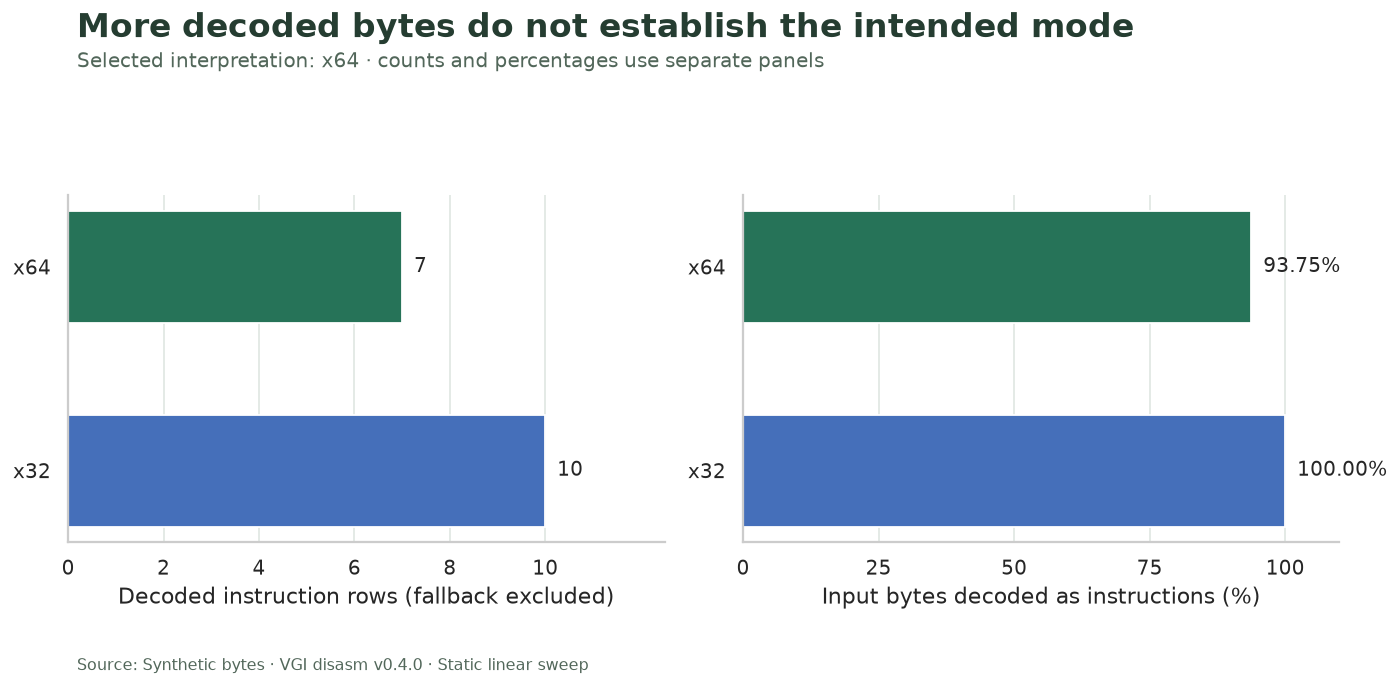

The x64 interpretation decodes **15/16 bytes (93.75%)**; x32 decodes **16/16 (100.00%)**. Yet this fixture was authored around a 64-bit sequence. A higher fraction cannot recover that provenance. Use container metadata or other independent architecture evidence for real inputs; decoding success alone is insufficient.

In [12]:
summary = globals()["summary"].set_index("mode").loc[modes].reset_index()
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.3))
mode_colors = ["#267358", "#456fba"]
for ax, column, xlabel, maximum in [
    (
        axes[0],
        "decoded_instructions",
        "Decoded instruction rows (fallback excluded)",
        max(summary.decoded_instructions) * 1.25,
    ),
    (axes[1], "decoded_percent", "Input bytes decoded as instructions (%)", 110),
]:
    ax.barh(modes, summary[column], color=mode_colors, height=0.55)
    for y, value in enumerate(summary[column]):
        text = f"{value:.2f}%" if column == "decoded_percent" else str(int(value))
        ax.text(value + maximum * 0.02, y, text, ha="left", va="center", fontsize=11)
    ax.set_xlim(0, maximum)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
axes[0].set_xticks(np.arange(0, int(max(summary.decoded_instructions)) + 1, 2))
axes[1].set_xticks([0, 25, 50, 75, 100])
finish(
    fig,
    "More decoded bytes do not establish the intended mode",
    f"Selected interpretation: {MODE} · counts and percentages use separate panels",
    f"decoding-profile-{MODE}.png",
)
a = summary.set_index("mode").loc["x64"]
b = summary.set_index("mode").loc["x32"]
prose(
    f"The x64 interpretation decodes **{a.decoded_bytes:.0f}/{a.input_bytes:.0f} bytes "
    f"({a.decoded_percent:.2f}%)**; x32 decodes **{b.decoded_bytes:.0f}/{b.input_bytes:.0f} "
    f"({b.decoded_percent:.2f}%)**. Yet this fixture was authored around a 64-bit sequence. "
    "A higher fraction cannot recover that provenance. Use container metadata or other "
    "independent architecture evidence for real inputs; decoding success alone is insufficient."
)

## Check byte accounting

Validate the transformation itself: concatenated row bytes reconstruct the input,
addresses cover it without gaps or overlaps, and fallback bytes remain distinct.
These checks do not assume that every byte decodes or that one mode is correct.

In [13]:
%%sql checks <<
WITH totals AS (
 SELECT mode, sum(size) AS total_size, string_agg(hex(bytes),'' ORDER BY address) AS rebuilt,
 min(address) AS first_address, max(address+size) AS end_address
 FROM decoded GROUP BY mode
), adjacent AS (
 SELECT *, lag(address+size) OVER (PARTITION BY mode ORDER BY address) AS previous_end
 FROM decoded
)
SELECT 'Both requested modes are present' AS check_name, abs(count(*)-2) AS violations FROM totals
UNION ALL
SELECT 'Every row length agrees with its returned bytes', count(*) FROM decoded
WHERE size <= 0 OR size <> octet_length(bytes)
UNION ALL
SELECT 'Ordered row bytes reconstruct the original input', count(*) FROM totals CROSS JOIN sample
WHERE rebuilt <> hex(payload) OR total_size <> octet_length(payload)
UNION ALL
SELECT 'Address span matches the fixed input extent', count(*) FROM totals CROSS JOIN sample
WHERE first_address <> base_address OR end_address <> base_address + octet_length(payload)
UNION ALL
SELECT 'Adjacent rows leave no gaps or overlaps', count(*) FROM adjacent
WHERE previous_end IS NOT NULL AND previous_end <> address
UNION ALL
SELECT 'Fallback rows consume exactly one byte', count(*) FROM decoded
WHERE mnemonic='.byte' AND size <> 1
UNION ALL
SELECT 'Missing architecture yields a zero-byte diagnostic', abs(count(*)-1)
 + count(*) FILTER (WHERE mnemonic <> '(error)' OR size <> 0 OR octet_length(bytes) <> 0)
FROM diagnostic
UNION ALL
SELECT 'Explicit-mode results contain no diagnostic rows', count(*) FROM decoded
WHERE mnemonic='(error)';

In [14]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "Byte accounting failed."
prose(
    f"All **{len(checks)} checks** pass. Both interpretations account for the same input, "
    "while their instruction boundaries, operand widths and fallback counts differ."
)

,check_name,violations
0,Both requested modes are present,0
1,Every row length agrees with its returned bytes,0
2,Ordered row bytes reconstruct the original input,0
3,Address span matches the fixed input extent,0
4,Adjacent rows leave no gaps or overlaps,0
5,Fallback rows consume exactly one byte,0
6,Missing architecture yields a zero-byte diagno...,0
7,Explicit-mode results contain no diagnostic rows,0


All **8 checks** pass. Both interpretations account for the same input, while their instruction boundaries, operand widths and fallback counts differ.

## One change to try

Predict the selected instruction count and fallback count, then change `MODE` to `"x32"`
and run all cells. Compare the selected SQL table, the outlined span row and the profile
summary. The byte string and both reference calculations should stay identical. Reset
to `"x64"` afterward.

Preserve the saved default with a separate executed copy:

```sh
uv run --locked python execute.py --parameters '{"MODE":"x32"}' \
  --output-dir validation/x32
```

This linear sweep does not follow branches, determine which instructions execute,
separate embedded data from code, or prove that a binary is benign or malicious.
For container-backed input, combine `format`, `entrypoint` and `sections` with the
instruction relation. The worker's capability indicators are separate heuristics;
this notebook does not infer capabilities from the synthetic instruction counts.

In [15]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)